# Day 4 — Is the Model Any Good? Then Ship It (HDFS early warning)

**First half (measure):** metrics for rare events, error slices, probability calibration, a cost-based alert threshold, and a regression detour.
**Second half (ship):** export to ONNX, benchmark latency, save a serving config. The FastAPI service lives in `src/logagent/service.py`.

Data discipline for today: the validation period is split in two by time:
- `val_cal` (first half): fit the calibrator
- `val_thr` (second half): choose the threshold and do error analysis
- `test`: touched **once**, at the end

In [1]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb, mlflow
from sklearn.frozen import FrozenEstimator
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, brier_score_loss,
                             mean_absolute_error, root_mean_squared_error, r2_score)

from logagent.splits import load_blocks, time_split, xy, EARLY_FEATURES, ROOT

SEED = 42
df = load_blocks()
train, val, test = time_split(df)
val_cal, val_thr = val.iloc[: len(val) // 2], val.iloc[len(val) // 2 :]
X_tr, y_tr = xy(train, EARLY_FEATURES)
X_cal, y_cal = xy(val_cal, EARLY_FEATURES)
X_thr, y_thr = xy(val_thr, EARLY_FEATURES)
X_te, y_te = xy(test, EARLY_FEATURES)
print({k: len(v) for k, v in dict(train=train, val_cal=val_cal, val_thr=val_thr, test=test).items()})

{'train': 402542, 'val_cal': 43129, 'val_thr': 43130, 'test': 86260}


## 0. Load the Day 3 model from the MLflow registry
We refit from the registered run's saved params + seed, and check it is identical to the registered model, which is reproducibility in practice.

In [2]:
mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")
client = mlflow.MlflowClient()
MODEL_NAME, MODEL_VERSION = "hdfs-anomaly-lgbm", "1"
mv = client.get_model_version(MODEL_NAME, MODEL_VERSION)

def cast(v):
    if v in ("True", "False"): return v == "True"
    for t in (int, float):
        try: return t(v)
        except ValueError: pass
    return v
params = {k: cast(v) for k, v in client.get_run(mv.run_id).data.params.items()}

model = lgb.LGBMClassifier(**params).fit(X_tr, y_tr)
registered = mlflow.lightgbm.load_model(f"models:/{MODEL_NAME}/{MODEL_VERSION}")
print("refit == registered model:", np.allclose(model.predict_proba(X_te)[:, 1], registered.predict(X_te)))
p_thr_raw = model.predict_proba(X_thr)[:, 1]

refit == registered model: True


## 1. Metrics for a rare event
With ~3% positives, **ROC-AUC** looks great almost automatically, because it rewards ranking the huge pile of normal blocks correctly.
**PR-AUC** only cares about how well we find the anomalies, so it's the honest headline metric here.

ROC-AUC = 0.711   PR-AUC = 0.401   (anomaly rate 3.09%)
              precision    recall  f1-score   support

      normal      0.979     1.000     0.989     41799
     anomaly      0.980     0.330     0.494      1331

    accuracy                          0.979     43130
   macro avg      0.980     0.665     0.741     43130
weighted avg      0.979     0.979     0.974     43130



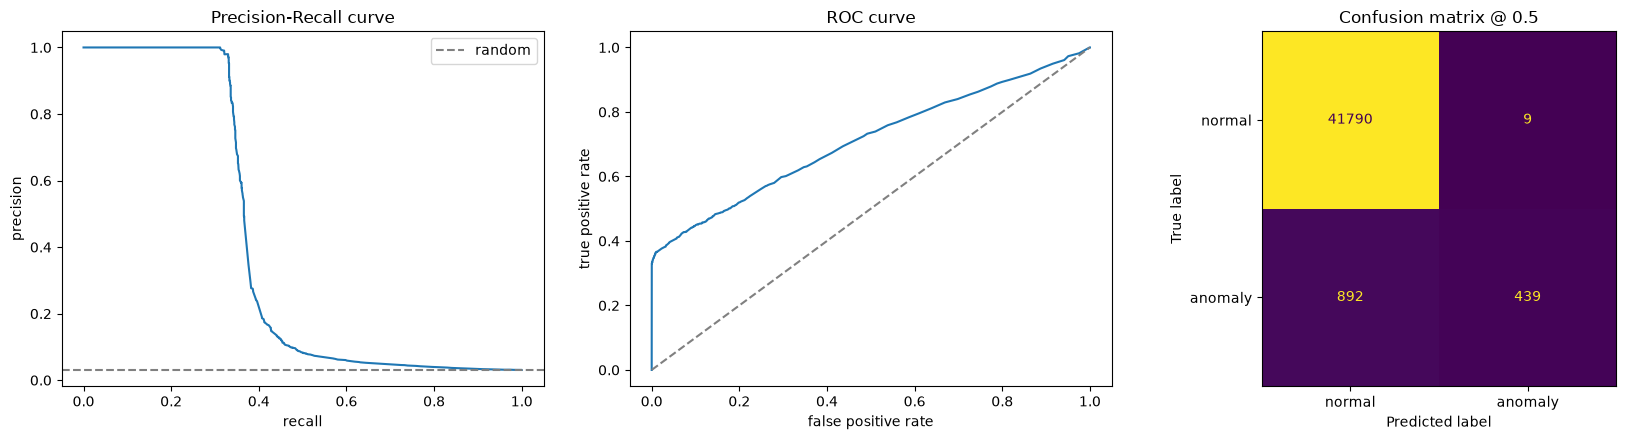

In [3]:
print(f"ROC-AUC = {roc_auc_score(y_thr, p_thr_raw):.3f}   PR-AUC = {average_precision_score(y_thr, p_thr_raw):.3f}   (anomaly rate {y_thr.mean():.2%})")
print(classification_report(y_thr, p_thr_raw >= 0.5, target_names=["normal", "anomaly"], digits=3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
prec, rec, _ = precision_recall_curve(y_thr, p_thr_raw)
axes[0].plot(rec, prec); axes[0].axhline(y_thr.mean(), ls="--", c="grey", label="random")
axes[0].set(xlabel="recall", ylabel="precision", title="Precision-Recall curve"); axes[0].legend()
fpr, tpr, _ = roc_curve(y_thr, p_thr_raw)
axes[1].plot(fpr, tpr); axes[1].plot([0, 1], [0, 1], ls="--", c="grey")
axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve")
ConfusionMatrixDisplay(confusion_matrix(y_thr, p_thr_raw >= 0.5), display_labels=["normal", "anomaly"]).plot(ax=axes[2], colorbar=False)
axes[2].set_title("Confusion matrix @ 0.5")
plt.tight_layout()

## 2. Error analysis: where does the model fail?
Slice the validation data and compare. One overall number hides where the model is weak.

In [4]:
ev = val_thr.assign(p=p_thr_raw, pred=p_thr_raw >= 0.5)
early_counts = ev[[c for c in EARLY_FEATURES if c != "early_elapsed"]]
ev["distinct_early_events"] = (early_counts > 0).sum(axis=1)
ev["elapsed_bucket"] = pd.qcut(ev["early_elapsed"], 4, duplicates="drop")

def slice_report(col):
    g = ev.groupby(col, observed=True)
    return pd.DataFrame({
        "blocks": g.size(),
        "anomaly_rate": g["label"].mean(),
        "recall@0.5": g.apply(lambda d: d.loc[d.label == 1, "pred"].mean() if d.label.any() else np.nan),
        "pr_auc": g.apply(lambda d: average_precision_score(d.label, d.p) if 0 < d.label.sum() < len(d) else np.nan),
    }).round(3)

display(slice_report("distinct_early_events"))
display(slice_report("elapsed_bucket"))

,blocks,anomaly_rate,recall@0.5,pr_auc
distinct_early_events,,,,
2,164,1.000,1.000,NaN
3,265,0.751,0.995,0.999
4,38725,0.021,0.004,0.038
5,3968,0.038,0.454,0.521
6,8,0.750,0.833,0.705


,blocks,anomaly_rate,recall@0.5,pr_auc
elapsed_bucket,,,,
"(-0.001, 30.0]",11069,0.058,0.681,0.731
"(30.0, 39.0]",11840,0.017,0.005,0.027
"(39.0, 47.0]",9739,0.019,0.000,0.021
"(47.0, 3064.0]",10482,0.028,0.003,0.063


In [5]:
# The anomalies we miss: what do their first events look like?
missed = ev[(ev.label == 1) & ~ev.pred]
caught = ev[(ev.label == 1) & ev.pred]
cmp = pd.DataFrame({"missed": (missed[early_counts.columns] > 0).mean(), "caught": (caught[early_counts.columns] > 0).mean()})
print(f"missed {len(missed)} of {len(missed) + len(caught)} anomalies at threshold 0.5")
cmp.assign(diff=cmp.missed - cmp.caught).sort_values("diff", key=abs, ascending=False).head(8).round(3)

missed 892 of 1331 anomalies at threshold 0.5


,missed,caught,diff
early_E9,0.999,0.164,0.835
early_E11,1.000,0.175,0.825
early_E7,0.000,0.453,-0.453
early_E13,0.000,0.118,-0.118
early_E26,0.092,0.007,0.085
early_E25,0.000,0.055,-0.055
early_E18,0.001,0.005,-0.003
early_E14,0.000,0.002,-0.002


## 3. Probability calibration
A calibrated model's "0.3" means "this happens about 30% of the time". We need that to set a threshold from **costs**.
Fit the calibrators on `val_cal` and evaluate them on `val_thr` (data they haven't seen).
- **Platt / sigmoid:** fits an S-curve on the model's log-odds. Simple, works with little data.
- **Isotonic:** a free-form increasing step function. More flexible, needs more data (we have ~43k rows).

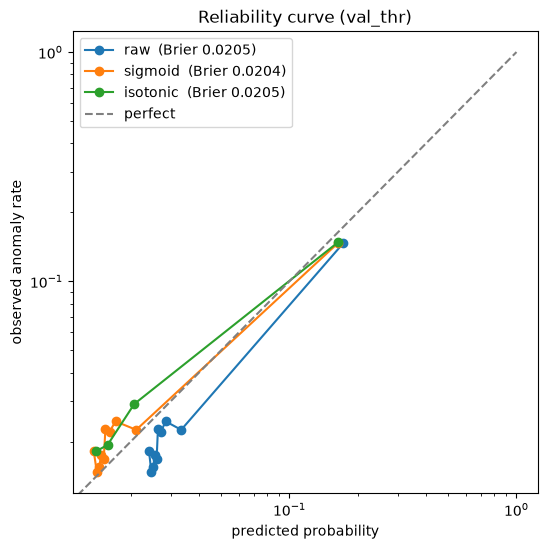

In [6]:
calibrated = {m: CalibratedClassifierCV(FrozenEstimator(model), method=m).fit(X_cal, y_cal) for m in ["sigmoid", "isotonic"]}
probs = {"raw": p_thr_raw, **{m: c.predict_proba(X_thr)[:, 1] for m, c in calibrated.items()}}

fig, ax = plt.subplots(figsize=(6, 6))
for name, p in probs.items():
    frac_pos, mean_pred = calibration_curve(y_thr, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=f"{name}  (Brier {brier_score_loss(y_thr, p):.4f})")
ax.plot([0, 1], [0, 1], ls="--", c="grey", label="perfect")
ax.set(xlabel="predicted probability", ylabel="observed anomaly rate", title="Reliability curve (val_thr)",
       xscale="log", yscale="log"); ax.legend();

In [7]:
for name, p in probs.items():
    print(f"{name:9s} Brier={brier_score_loss(y_thr, p):.5f}  PR-AUC={average_precision_score(y_thr, p):.3f}  distinct values={len(np.unique(p))}")

raw       Brier=0.02049  PR-AUC=0.401  distinct values=512
sigmoid   Brier=0.02045  PR-AUC=0.401  distinct values=512
isotonic  Brier=0.02049  PR-AUC=0.378  distinct values=19


**Reading it:** this LightGBM model (trained on log-loss) is already close to calibrated, so the Brier gains are tiny.
That's a valid outcome: you *check* calibration, you don't assume you need it.

We ship **sigmoid (Platt)**:
- It's monotonic and smooth, so the ranking and PR-AUC are unchanged.
- It is just two numbers (`a`, `b`).
- It is robust when serving: ONNX computes in float32, and isotonic's step jumps sit exactly on LightGBM's repeated output values, so tiny rounding differences can flip a calibrated value (we hit this). Isotonic's ties also lower PR-AUC here.

In [8]:
cal = calibrated["sigmoid"]
p_thr = probs["sigmoid"]

## 4. Choosing the alert threshold from costs
0.5 is an arbitrary default. Ask what each mistake costs:
- **False negative** (missed failure): the block fails silently and becomes an incident → say **50 units**
- **False positive** (false page): someone looks for a few minutes → **1 unit**

For calibrated probabilities the theory says alert when `p > C_FP / (C_FP + C_FN)` = 1/51 ≈ **0.02**.
Let's check that empirically on `val_thr`.

,threshold,cost
default 0.5,0.500,44563
theory,0.020,40459
empirical best,0.015,38358


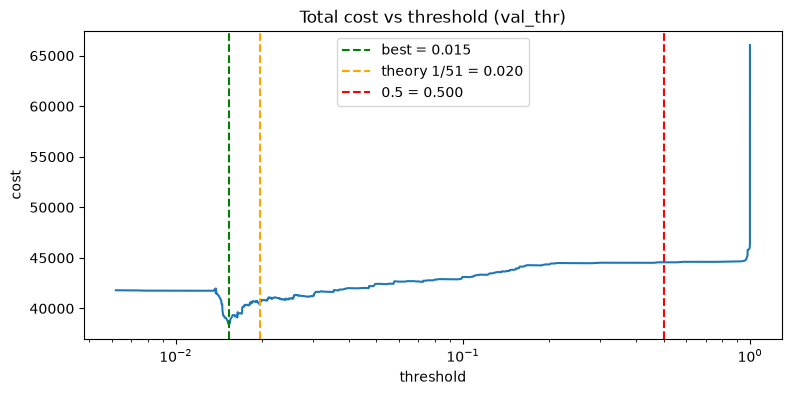

In [9]:
COST_FN, COST_FP = 50, 1

def total_cost(y, p, t):
    tn, fp, fn, tp = confusion_matrix(y, p >= t, labels=[0, 1]).ravel()
    return COST_FN * fn + COST_FP * fp

# Candidate cut-offs sit *between* the model's distinct output values, so no score lands exactly on the threshold
vals = np.unique(p_thr)
thresholds = (vals[1:] + vals[:-1]) / 2
costs = np.array([total_cost(y_thr, p_thr, t) for t in thresholds])
best_t = float(thresholds[costs.argmin()])
theory_t = COST_FP / (COST_FP + COST_FN)

ax = pd.Series(costs, index=thresholds).plot(logx=True, figsize=(9, 4), title="Total cost vs threshold (val_thr)")
for t, c, lab in [(best_t, "green", "best"), (theory_t, "orange", "theory 1/51"), (0.5, "red", "0.5")]:
    ax.axvline(t, c=c, ls="--", label=f"{lab} = {t:.3f}")
ax.set(xlabel="threshold", ylabel="cost"); ax.legend()

pd.DataFrame({"threshold": [0.5, theory_t, best_t],
              "cost": [total_cost(y_thr, p_thr, t) for t in (0.5, theory_t, best_t)]},
             index=["default 0.5", "theory", "empirical best"]).round(3)

## 5. Final test, run once
Calibrated probabilities plus the chosen threshold, on the untouched test period. Compare against the trivial policies
("never alert", "alert on everything") so the cost number has context.

In [10]:
THRESHOLD = best_t
p_te = cal.predict_proba(X_te)[:, 1]
cm = confusion_matrix(y_te, p_te >= THRESHOLD)
tn, fp, fn, tp = cm.ravel()
print(f"test PR-AUC={average_precision_score(y_te, p_te):.3f}  threshold={THRESHOLD:.3f}")
print(f"caught {tp}/{tp + fn} failures (recall {tp / (tp + fn):.1%}), {fp} false pages (precision {tp / max(tp + fp, 1):.1%})")
pd.Series({"model @ threshold": total_cost(y_te, p_te, THRESHOLD),
           "never alert": COST_FN * y_te.sum(),
           "alert on everything": COST_FP * (1 - y_te).sum(),
           "model @ 0.5": total_cost(y_te, p_te, 0.5)}, name="test cost")

test PR-AUC=0.837  threshold=0.015
caught 1036/1116 failures (recall 92.8%), 43100 false pages (precision 2.3%)


model @ threshold      47100
never alert            55800
alert on everything    85144
model @ 0.5             9807
Name: test cost, dtype: int64

**Honest reading:** compare the first and last rows. The threshold that minimised cost on the validation period
**does not transfer** to the test period: there it raises far more false pages than 0.5 would. Why:
- The validation period was full of failures that look normal in their first 8 events (the error analysis above showed
  most misses have the ordinary E9/E11 pattern). Catching them needed a very low cut-off.
- The test period has a lower anomaly rate (≈1.3% vs ≈3.1%) and a different failure mix, so probabilities calibrated on
  validation are too high there, and a low cut-off fires constantly.
- On validation the cost curve was also fairly flat (only a modest saving versus 0.5), a hint that the choice was fragile.

What we must **not** do now is re-pick the threshold by looking at test, which would leak test into the model and make
the number meaningless. The right moves are process changes: re-check calibration and threshold on the most recent data
before each release, prefer robust thresholds when the cost curve is flat, and monitor the alert rate in production
(Day 11 drift checks). We ship the threshold our protocol produced and record this as a known risk.

## 6. The same workflow for regression
Not every question is yes/no. **How many log events will this block produce in total?** (`n_events`) is a number, so we use regression.

**A trap first: censoring.** Our logs stop after ~38 h. A block first seen near the end *can't* show a long life or many
events, so lifetime-type targets shrink over time for reasons unrelated to the block itself:

In [11]:
print(train["latency"].mean().round(), val["latency"].mean().round(), test["latency"].mean().round(), "<- mean latency (s): train / val / test")

23127.0 3053.0 949.0 <- mean latency (s): train / val / test


Fix: only use blocks whose **whole lifetime fits inside the log window** (first seen at least max-lifetime before the end),
then split that subset by time.

Compare a **linear** model, a **polynomial** model (degree 2, interactions between events) and LightGBM, scored with:
- **MAE**: average absolute error, in seconds (easy to explain)
- **RMSE**: punishes big misses more
- **R²**: share of variance explained (1 = perfect, 0 = no better than predicting the mean)

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge

cutoff = df["first_ts"].max() - pd.Timedelta(seconds=float(df["latency"].max()))
reg_train, reg_val, _ = time_split(df[df["first_ts"] <= cutoff])
sub = reg_train.sample(100_000, random_state=SEED)
Xr_tr, yr_tr = sub[EARLY_FEATURES], sub["n_events"]
Xr_va, yr_va = reg_val[EARLY_FEATURES], reg_val["n_events"]
regs = {
    "mean (baseline)": None,
    "linear": make_pipeline(StandardScaler(), LinearRegression()),
    "polynomial deg 2": make_pipeline(StandardScaler(), PolynomialFeatures(2), Ridge(alpha=1.0)),
    "lightgbm": lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=SEED, verbose=-1),
}
rows = {}
for name, r in regs.items():
    pred = np.full(len(yr_va), yr_tr.mean()) if r is None else r.fit(Xr_tr, yr_tr).predict(Xr_va)
    rows[name] = {"MAE (events)": mean_absolute_error(yr_va, pred), "RMSE (events)": root_mean_squared_error(yr_va, pred), "R2": r2_score(yr_va, pred)}
pd.DataFrame(rows).T.round(3)

,MAE (events),RMSE (events),R2
mean (baseline),2.249,4.115,-0.017
linear,1.922,3.826,0.121
polynomial deg 2,2.026,12.000,-7.652
lightgbm,1.853,3.489,0.269


Eight events only partly predict a block's total activity, so expect a modest R². RMSE > MAE because a few blocks with
hundreds of events dominate the squared error. R² below 0 means "worse than predicting the mean". The polynomial model
shows this: with 465 squared/interaction terms it fits training data but produces wild predictions on unusual validation
blocks (huge RMSE). More flexible isn't automatically better; this is the overfitting idea you'll see again on Day 5.

---
# Second half: package and ship

## 7. Export to ONNX
ONNX is a portable model format. The service only needs `onnxruntime` (small, fast) instead of LightGBM + scikit-learn.
The sigmoid calibrator is `p = 1 / (1 + exp(a · logit(p_raw) + b))`, so we export `a` and `b` to JSON.

In [13]:
import onnxmltools, onnxruntime as ort
from onnxmltools.convert.common.data_types import FloatTensorType

MODELS = ROOT / "models"
onnx_model = onnxmltools.convert_lightgbm(model, initial_types=[("input", FloatTensorType([None, len(EARLY_FEATURES)]))],
                                          zipmap=False, target_opset=15)
(MODELS / "hdfs_lgbm.onnx").write_bytes(onnx_model.SerializeToString())
sess = ort.InferenceSession(str(MODELS / "hdfs_lgbm.onnx"), providers=["CPUExecutionProvider"])
print("inputs:", [i.name for i in sess.get_inputs()], " outputs:", [o.name for o in sess.get_outputs()])

X_te32 = X_te.to_numpy(np.float32)
p_onnx = sess.run(["probabilities"], {"input": X_te32})[0][:, 1]
print("max |ONNX - LightGBM| =", float(np.abs(p_onnx - model.predict_proba(X_te)[:, 1]).max()))

sig = cal.calibrated_classifiers_[0].calibrators[0]
CAL_A, CAL_B = float(sig.a_), float(sig.b_)

def calibrate(p_raw):
    p_raw = np.clip(p_raw.astype(np.float64), 1e-12, 1 - 1e-12)
    return 1 / (1 + np.exp(CAL_A * np.log(p_raw / (1 - p_raw)) + CAL_B))

p_onnx_cal = calibrate(p_onnx)
print("max |ONNX+sigmoid - calibrated sklearn| =", float(np.abs(p_onnx_cal - p_te).max()))
print("alerts that differ on test:", int(((p_onnx_cal >= THRESHOLD) != (p_te >= THRESHOLD)).sum()), "of", len(p_te))

inputs: ['input']  outputs: ['label', 'probabilities']


max |ONNX - LightGBM| = 1.8327991369027075e-07
max |ONNX+sigmoid - calibrated sklearn| = 2.403054907285096e-07
alerts that differ on test: 0 of 86260


In [14]:
serving_config = {
    "model_name": MODEL_NAME, "model_version": MODEL_VERSION,
    "features": EARLY_FEATURES, "threshold": THRESHOLD,
    "calibration": {"method": "sigmoid_on_logit", "a": CAL_A, "b": CAL_B},
    "costs": {"false_negative": COST_FN, "false_positive": COST_FP},
}
(MODELS / "serving_config.json").write_text(json.dumps(serving_config, indent=1))

# Golden examples: inputs + expected outputs, used by the service tests (and later the CI gate on Day 11)
traces = pd.read_csv(ROOT / "data/raw/preprocessed/Event_traces.csv", usecols=["BlockId", "Features", "TimeInterval"]).set_index("BlockId")
gold = pd.concat([test[test.label == 1].sample(5, random_state=SEED), test[test.label == 0].sample(5, random_state=SEED)])
golden = []
for (_, row), p in zip(gold.iterrows(), calibrate(sess.run(["probabilities"], {"input": gold[EARLY_FEATURES].to_numpy(np.float32)})[0][:, 1])):
    t = traces.loc[row.block_id]
    golden.append({"block_id": row.block_id, "label": int(row.label),
                   "events": t.Features.strip("[]").split(",")[:8],
                   "elapsed_seconds": float(row.early_elapsed), "expected_p": float(p)})
(ROOT / "tests" / "golden.json").write_text(json.dumps(golden, indent=1))
print(f"saved serving config (threshold={THRESHOLD:.3f}) and {len(golden)} golden examples")

saved serving config (threshold=0.015) and 10 golden examples


## 8. Latency: native vs ONNX Runtime
Single-request latency is what a user feels; batch throughput is what a log pipeline needs.

In [15]:
def bench(fn, n):
    fn()  # warm-up
    t = time.perf_counter()
    for _ in range(n): fn()
    return (time.perf_counter() - t) / n * 1000

one_df, one_np = X_te.iloc[[0]], X_te32[[0]]
batch_df, batch_np = X_te.iloc[:1000], X_te32[:1000]
lat = pd.DataFrame({
    "1 row (ms)": [bench(lambda: model.predict_proba(one_df), 300), bench(lambda: sess.run(["probabilities"], {"input": one_np}), 3000)],
    "1000 rows (ms)": [bench(lambda: model.predict_proba(batch_df), 30), bench(lambda: sess.run(["probabilities"], {"input": batch_np}), 300)],
}, index=["LightGBM (sklearn API)", "ONNX Runtime"]).round(3)
lat["speed-up 1 row"] = (lat.iloc[0, 0] / lat["1 row (ms)"]).round(1)
lat

,1 row (ms),1000 rows (ms),speed-up 1 row
LightGBM (sklearn API),0.761,2.663,1.0
ONNX Runtime,0.016,1.797,47.6


In [16]:
mlflow.set_experiment("day4-evaluate-ship")
with mlflow.start_run(run_name="calibrated_onnx"):
    mlflow.log_params({"source_model": f"{MODEL_NAME}/v{MODEL_VERSION}", "calibration": "sigmoid",
                       "threshold": THRESHOLD, "cost_fn": COST_FN, "cost_fp": COST_FP})
    mlflow.log_metrics({"test_pr_auc": average_precision_score(y_te, p_te), "test_cost": total_cost(y_te, p_te, THRESHOLD),
                        "test_recall": tp / (tp + fn), "test_precision": tp / max(tp + fp, 1),
                        "onnx_latency_1row_ms": lat.iloc[1, 0], "native_latency_1row_ms": lat.iloc[0, 0]})
    mlflow.log_artifact(str(MODELS / "hdfs_lgbm.onnx")); mlflow.log_artifact(str(MODELS / "serving_config.json"))
print("logged to MLflow")

logged to MLflow


## 9. Serve it
The service (`src/logagent/service.py`) takes the **raw first events** of a block, builds features with the *same*
`logagent.features` code used in training, runs ONNX, calibrates, and applies the threshold.

```bash
uv run uvicorn logagent.service:app --port 8000          # local
uv run pytest -q                                         # tests incl. golden examples
docker build -t hdfs-early-warning . && docker run -p 8000:8000 hdfs-early-warning
curl -s localhost:8000/predict -H 'content-type: application/json' \
     -d '{"events": ["E5","E22","E5","E5","E11","E9","E11","E9"], "elapsed_seconds": 1.0}'
```

## End-of-day checklist
- [x] Evaluation report: PR vs ROC, confusion matrix, error slices
- [x] Calibrated probabilities (reliability curve + Brier)
- [x] Threshold chosen from a cost table, test evaluated once
- [x] Regression workflow (linear / polynomial / LightGBM; MAE, RMSE, R²)
- [x] ONNX export verified against the original model, latency compared
- [x] FastAPI service + tests + Dockerfile (Part 1 complete)